# Alpha (For You content share in feed) dose-response scan — summary figures

Summarizes `scripts/alpha_dose_response_broad_scan.py`'s results
(`docs/report/2026-09-11-alpha-dose-response-broad-scan.md` and the follow-up discussion in chat).
6 alpha points x 20 seeds, n=1000, steps=20000. Checkpoints shown: **step=10000** and **step=20000**
(not step=40000 — these runs only went to 20000 steps; 10000 is used as the earlier comparison point
instead, per user decision 2026-09-24).

In [1]:
import csv
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

ROOT = Path(".").resolve()
if ROOT.name == "scripts":
    ROOT = ROOT.parent

ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
BASE_SEED = 9100000
N_SEEDS = 20
CHECKPOINTS = [10000, 20000]

COLORS = {10000: "#1baf7a", 20000: "#2a78d6"}  # dataviz-skill-style categorical palette
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                      "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})


## 1. Simulation configuration (Java-side agent/model parameters)

The only manipulated variable across the scan is `alpha` (`feedAlgoShare` — the **share of each
agent's feed filled by the opinion-blind, repost-velocity-ranked "For You" content**, vs. the
remainder filled chronologically from followees; 0=fully chronological/follower feed, 1=fully
algorithmic "For You" feed). Everything else below is held fixed at this repo's inherited,
previously-validated baseline config (`scripts/feed_redesign_v5_dose_response_n100.py`'s
`FIXED_TOKENS`).

In [2]:
RUN_META = {
    "n (agents)": 1000, "steps": 20000, "network": "Holme-Kim (hk)", "seeds/alpha": N_SEEDS,
    "alpha grid": ALPHAS,
}

FIXED_TOKENS = {
    # --- network topology ---
    "hk_m": 15, "hk_a": 4, "hk_pt": 0.05, "max_follow": 43.8638, "follow_prob": 0.01,
    # --- recommendation / feed mechanism (everything except alpha itself) ---
    "feed_capacity": 15, "hop": 4, "feed_decay_mode": "exp",
    "feed_decay_lambda": 0.10992130598108527, "feed_time_decay_tau": 30,
    # --- agent behavior: posting / reposting ---
    "access_prob": 0.1, "repost_prob": 0.1, "relay_enabled": False,
    "out_of_bc_repost_prob": 0.01, "rel_attrib": "original",
    "initial_pp": 0.25537, "max_pp": 1.0, "min_pp": 0.01, "pp_relax_eta": 0.100000,
    # --- bounded confidence (opinion-update tolerance) dynamics ---
    "p_u": 0.05, "bc_dec": 0.500000, "bc_recovery": 0.000100, "bc_floor": 0.2,
    "bc_ceiling": 1.0, "bc_init": 0.800000, "vocal_comfort_radius": 0.1,
    # --- initial network pruning / eviction ---
    "stub_dist": "uniform", "stub_min": 0.82, "stub_max": 0.82,
    "evict_beta": -1, "init_prune": "trim",
    # --- opinion-class binning (5 bins, used throughout this notebook) ---
    "neutral_band": 0.2,
}

print("Run metadata:")
for k, v in RUN_META.items():
    print(f"  {k:>16s}: {v}")
print()
print("Fixed config (identical across all alpha points):")
pd.DataFrame(sorted(FIXED_TOKENS.items()), columns=["param", "value"])


Run metadata:
        n (agents): 1000
             steps: 20000
           network: Holme-Kim (hk)
       seeds/alpha: 20
        alpha grid: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

Fixed config (identical across all alpha points):


,param,value
0,access_prob,0.1
1,bc_ceiling,1.0
2,bc_dec,0.5
3,bc_floor,0.2
4,bc_init,0.8
5,bc_recovery,0.0001
6,evict_beta,-1
7,feed_capacity,15
8,feed_decay_lambda,0.109921
9,feed_decay_mode,exp


**Opinion-class binning used throughout (5 equal-width bins over opinion in [-1, 1],
`Agent.java`'s `opinionClass` formula, class = floor((opinion+1)/0.4) capped at 4):**
class 0 = extreme(-), 1 = moderate(-), 2 = neutral, 3 = moderate(+), 4 = extreme(+).
"E" below = class 0 + class 4, "M" = class 1 + class 3, "N" = class 2.

## 2. Overall effect of alpha

Five outcomes, each defined in plain language on first use (per this project's convention of not
using a metric without saying exactly what it counts):

- **apparent polarization** = `postOpinionVar - opinionVar`: how much more spread out the
  opinions among what actually gets **posted** that step are, compared to the spread of opinions
  the *population actually holds*. Positive means the vocal/expressed layer looks more polarized
  than the population really is (this is the same comparison as `SF1 = postOpinionVar / opinionVar`
  discussed in the design doc, just as a difference instead of a ratio).
- **post count (windowed)** = `originalPostCount + repostCount` at that single step (this
  results.csv field is a **per-step** count, reset every step in the simulator — not a running
  cumulative total since the run started).
- **internal opinion polarization** = `opinionVar`: variance of agents' actual held opinions
  (the population's real attitude spread).
- **posted opinion polarization** = `postOpinionVar`: variance of opinions among posts actually
  made that step (the *expressed*/vocal layer — the same quantity apparent polarization compares
  against `opinionVar` above).
- **disagreement** = the `disagreement` column (`Analysis.computeDisagreement`): mean opinion
  distance between interacting agent pairs on the follow graph.

In [3]:
def read_row_at_step(results_csv_path, step):
    with open(results_csv_path, newline="") as f:
        for row in csv.DictReader(f):
            if int(row["step"]) == step:
                return row
    return None


records = []
for a in ALPHAS:
    ai = ALPHAS.index(a)
    for s in range(N_SEEDS):
        seed = BASE_SEED + ai * 1000 + s
        hits = glob.glob(str(ROOT / f"results/run_{seed}_*/metrics/results.csv"))
        if not hits:
            continue
        for chk in CHECKPOINTS:
            row = read_row_at_step(hits[0], chk)
            if row is None:
                continue
            records.append(dict(
                alpha=a, seed=seed, step=chk,
                opinionVar=float(row["opinionVar"]),
                postOpinionVar=float(row["postOpinionVar"]),
                disagreement=float(row["disagreement"]),
                originalPostCount=int(row["originalPostCount"]),
                repostCount=int(row["repostCount"]),
                postShare_0=float(row["postShare_0"]), postShare_1=float(row["postShare_1"]),
                postShare_2=float(row["postShare_2"]), postShare_3=float(row["postShare_3"]),
                postShare_4=float(row["postShare_4"]),
            ))

df = pd.DataFrame(records)
df["apparentPolarization"] = df["postOpinionVar"] - df["opinionVar"]
df["postCountWindowed"] = df["originalPostCount"] + df["repostCount"]
df["E_share"] = df["postShare_0"] + df["postShare_4"]
df["M_share"] = df["postShare_1"] + df["postShare_3"]
df["N_share"] = df["postShare_2"]

print(f"{len(df)} (alpha, seed, step) rows loaded "
      f"({df.groupby(['alpha','step']).size().min()}-{df.groupby(['alpha','step']).size().max()} seeds/cell)")
df.head()


240 (alpha, seed, step) rows loaded (20-20 seeds/cell)


,alpha,seed,step,opinionVar,postOpinionVar,disagreement,originalPostCount,repostCount,postShare_0,postShare_1,postShare_2,postShare_3,postShare_4,apparentPolarization,postCountWindowed,E_share,M_share,N_share
0,0.0,9100000,10000,0.2194,0.1711,0.1777,25,48,0.1600,0.1200,0.5600,0.0400,0.1200,-0.0483,73,0.2800,0.1600,0.5600
1,0.0,9100000,20000,0.2189,0.2046,0.1137,36,43,0.2222,0.0833,0.4444,0.1667,0.0833,-0.0143,79,0.3055,0.2500,0.4444
2,0.0,9100001,10000,0.2107,0.1510,0.2023,32,38,0.0313,0.5000,0.0313,0.3750,0.0625,-0.0597,70,0.0938,0.8750,0.0313
3,0.0,9100001,20000,0.2158,0.2250,0.1432,36,37,0.0833,0.3333,0.1667,0.2500,0.1667,0.0092,73,0.2500,0.5833,0.1667
4,0.0,9100002,10000,0.2380,0.2434,0.1676,54,25,0.1111,0.2037,0.2407,0.2407,0.2037,0.0054,79,0.3148,0.4444,0.2407


In [4]:
def agg(df, cols):
    g = df.groupby(["alpha", "step"])[cols].agg(["mean", "sem"]).reset_index()
    return g


metric_cols = ["apparentPolarization", "postCountWindowed", "opinionVar", "postOpinionVar", "disagreement"]
metric_labels = {
    "apparentPolarization": "Apparent polarization\n(postOpinionVar − opinionVar)",
    "postCountWindowed": "Post count (windowed,\noriginal+repost, this step)",
    "opinionVar": "Internal opinion polarization\n(opinionVar)",
    "postOpinionVar": "Posted opinion polarization\n(postOpinionVar)",
    "disagreement": "Disagreement",
}

summary = agg(df, metric_cols)
summary.head()


alpha   step apparentPolarization           postCountWindowed            \
                               mean       sem              mean       sem   
0   0.0  10000            -0.024435  0.006896             81.15  2.282975   
1   0.0  20000            -0.016010  0.007451             92.20  3.035405   
2   0.2  10000             0.049305  0.015768            131.60  3.735604   
3   0.2  20000             0.037585  0.013065            139.00  5.150370   
4   0.4  10000             0.054345  0.012892            148.40  4.750845   

  opinionVar           postOpinionVar           disagreement            
        mean       sem           mean       sem         mean       sem  
0   0.222560  0.002434       0.198125  0.008112     0.163870  0.007712  
1   0.223435  0.002328       0.207425  0.007750     0.106870  0.007540  
2   0.208785  0.002653       0.258090  0.017148     0.179775  0.003173  
3   0.207395  0.002558       0.244980  0.014450     0.153640  0.003255  
4   0.208495  0.003881       0.262840  0.015185     0.178390  0.002802

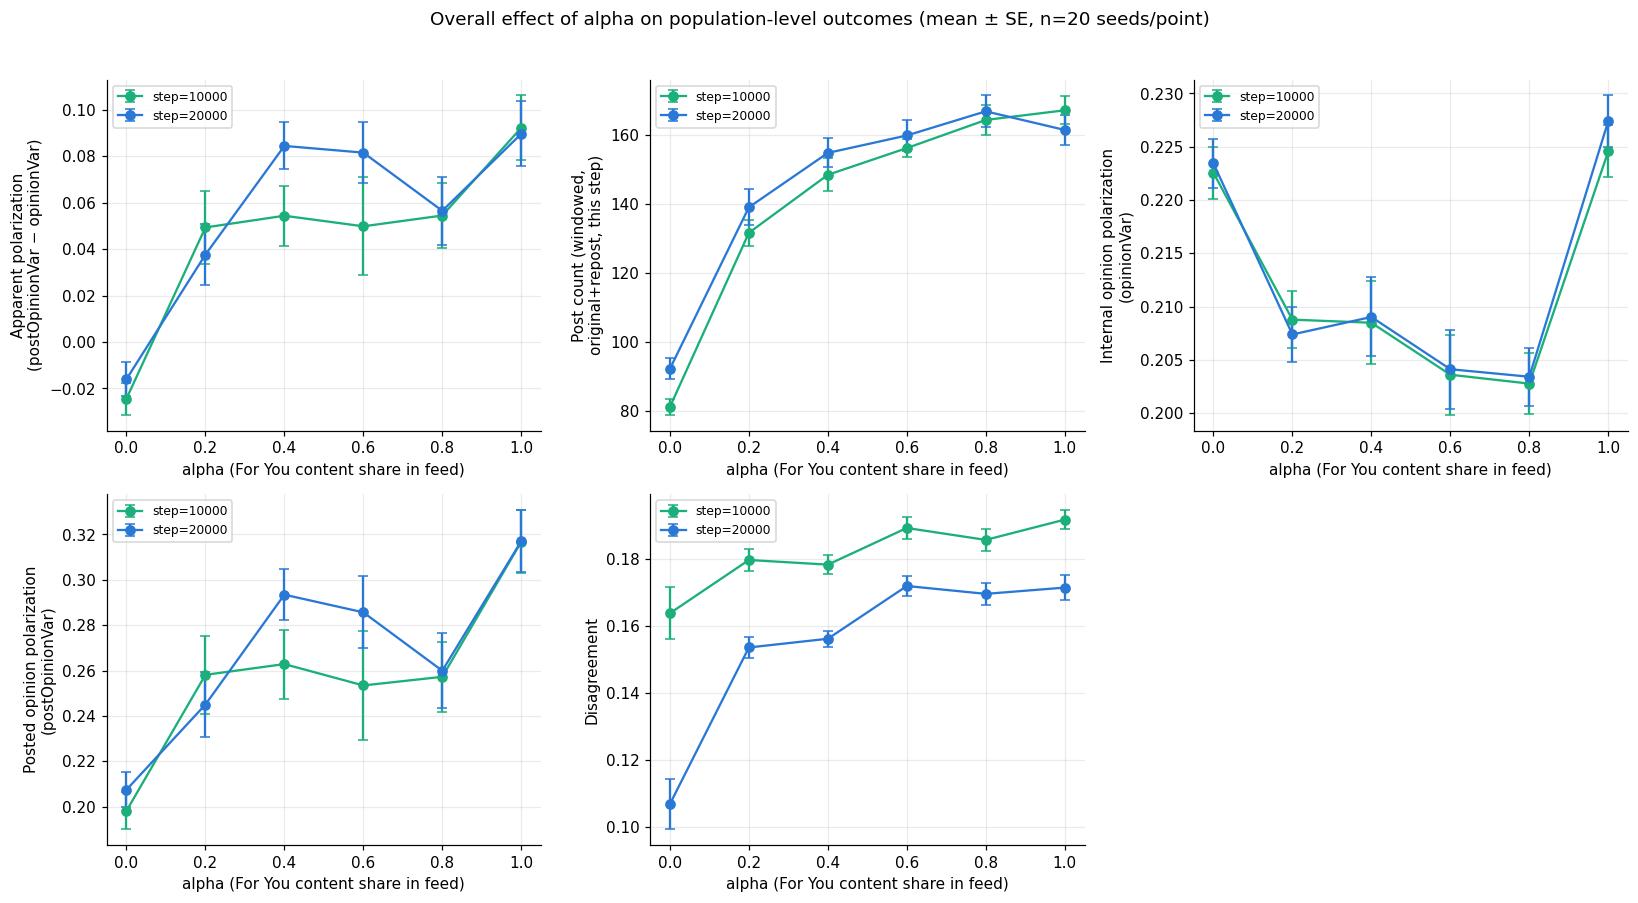

In [5]:
ALPHA_XLABEL = "alpha (For You content share in feed)"

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(metric_cols):
    ax = axes[i]
    for chk in CHECKPOINTS:
        sub = summary[summary["step"] == chk].sort_values("alpha")
        ax.errorbar(sub["alpha"], sub[(col, "mean")], yerr=sub[(col, "sem")],
                    marker="o", capsize=3, color=COLORS[chk], label=f"step={chk}")
    ax.set_xlabel(ALPHA_XLABEL)
    ax.set_ylabel(metric_labels[col])
    ax.xaxis.set_major_locator(mticker.FixedLocator(ALPHAS))
    ax.legend(fontsize=8)

axes[-1].axis("off")
fig.suptitle("Overall effect of alpha on population-level outcomes (mean ± SE, n=20 seeds/point)",
             y=1.02, fontsize=12)
fig.tight_layout()
plt.savefig(ROOT / "docs/report/alpha_scan_overall_effects.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Post share by camp (E / M / N)

Share of that step's total posting activity (`postShare_i`, already a same-step ratio, not
cumulative) contributed by each aggregated camp: **E** = extreme(−)+extreme(+) (classes 0+4),
**M** = moderate(−)+moderate(+) (classes 1+3), **N** = neutral (class 2).

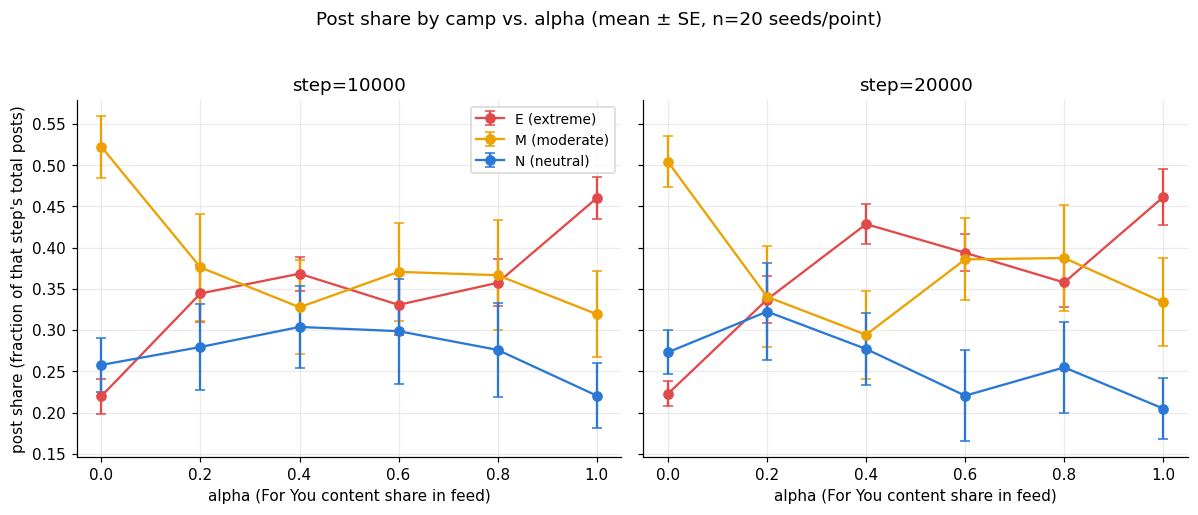

In [6]:
share_cols = ["E_share", "M_share", "N_share"]
share_labels = {"E_share": "E (extreme)", "M_share": "M (moderate)", "N_share": "N (neutral)"}
share_colors = {"E_share": "#e34948", "M_share": "#eda100", "N_share": "#2a78d6"}

share_summary = agg(df, share_cols)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

for ax, chk in zip(axes, CHECKPOINTS):
    sub = share_summary[share_summary["step"] == chk].sort_values("alpha")
    for col in share_cols:
        ax.errorbar(sub["alpha"], sub[(col, "mean")], yerr=sub[(col, "sem")],
                    marker="o", capsize=3, color=share_colors[col], label=share_labels[col])
    ax.set_xlabel(ALPHA_XLABEL)
    ax.set_title(f"step={chk}")
    ax.xaxis.set_major_locator(mticker.FixedLocator(ALPHAS))

axes[0].set_ylabel("post share (fraction of that step's total posts)")
axes[0].legend(fontsize=9)
fig.suptitle("Post share by camp vs. alpha (mean ± SE, n=20 seeds/point)", y=1.03, fontsize=12)
fig.tight_layout()
plt.savefig(ROOT / "docs/report/alpha_scan_camp_post_share.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Absolute post count by camp (E / M / N)

The share plot above (§3) only shows each camp's *fraction* of that step's posts, which can hide
how differently the camps behave in absolute terms if the *total* post count is also changing
with alpha (it is — see §2's post-count panel). Here: `camp_share x postCountWindowed`, i.e. the
actual number of posts+reposts attributable to each camp that step. This is where the extremes'
asymmetric growth is visible directly, rather than only as an eroding share for the other two
camps.

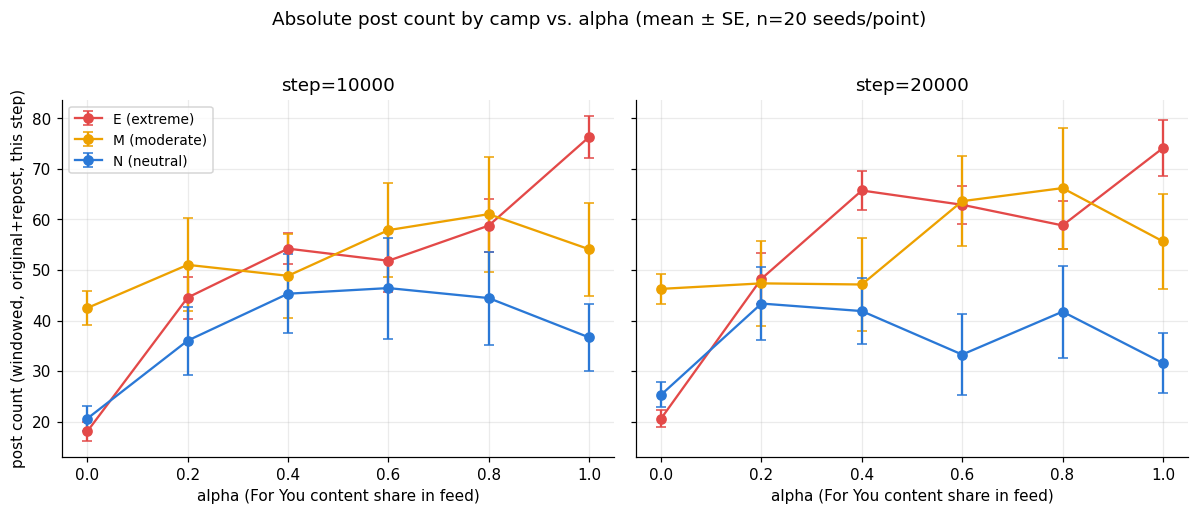

In [7]:
df["E_count"] = df["E_share"] * df["postCountWindowed"]
df["M_count"] = df["M_share"] * df["postCountWindowed"]
df["N_count"] = df["N_share"] * df["postCountWindowed"]

count_cols = ["E_count", "M_count", "N_count"]
count_labels = {"E_count": "E (extreme)", "M_count": "M (moderate)", "N_count": "N (neutral)"}
count_colors = share_colors  # same E/M/N palette as §3

count_summary = agg(df, count_cols)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

for ax, chk in zip(axes, CHECKPOINTS):
    sub = count_summary[count_summary["step"] == chk].sort_values("alpha")
    for col in count_cols:
        ax.errorbar(sub["alpha"], sub[(col, "mean")], yerr=sub[(col, "sem")],
                    marker="o", capsize=3, color=count_colors[col.replace("count", "share")],
                    label=count_labels[col])
    ax.set_xlabel(ALPHA_XLABEL)
    ax.set_title(f"step={chk}")
    ax.xaxis.set_major_locator(mticker.FixedLocator(ALPHAS))

axes[0].set_ylabel("post count (windowed, original+repost, this step)")
axes[0].legend(fontsize=9)
fig.suptitle("Absolute post count by camp vs. alpha (mean ± SE, n=20 seeds/point)", y=1.03, fontsize=12)
fig.tight_layout()
plt.savefig(ROOT / "docs/report/alpha_scan_camp_post_count.png", dpi=150, bbox_inches="tight")
plt.show()
